Wejdz na stronę https://www.quickmaptools.com/download-satellite-imagery i pobierz własny dowolnie wybrany raster (Sentinel-2) w kanałach RGB. Za pomocą rasterio wykonaj dla niego następujące zadania:

In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

1. Wyświetl raster w kolorach możliwie odzwierciedlających rzeczywistość

[[[1637 1909 2000 ... 3883 3817 3539]
  [1390 1844 2137 ... 3803 3678 3603]
  [1473 2041 2185 ... 3556 3384 3227]
  ...
  [4270 4191 3905 ... 2537 2544 2406]
  [4401 4064 3751 ... 2703 2656 2366]
  [3778 3671 3641 ... 2577 2526 2414]]

 [[1538 1787 2013 ... 3051 2956 2838]
  [1391 1697 1987 ... 2945 2893 2776]
  [1531 1916 2029 ... 2752 2664 2649]
  ...
  [3899 3864 3695 ... 2198 2257 2130]
  [3930 3664 3439 ... 2267 2263 2005]
  [3471 3365 3439 ... 2216 2179 2028]]

 [[1329 1525 1666 ... 2421 2334 2208]
  [1177 1521 1765 ... 2313 2247 2162]
  [1292 1687 1735 ... 2130 2051 2054]
  ...
  [3411 3300 3233 ... 1743 1772 1715]
  [3435 3128 3003 ... 1895 1825 1645]
  [2924 2808 2909 ... 1820 1793 1688]]]


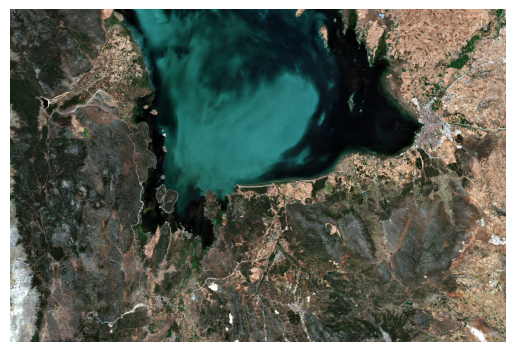

In [2]:
path_to_files = "../dane/raster/"
path = path_to_files + "sentinel-2-l2a_2026-08-28_S2C_MSIL2A_20260828T083601_R064_T36SUG_20260828T140219_"

with rasterio.open(path + "B04.tif") as src:
    red = src.read(1)

with rasterio.open(path + "B03.tif") as src:
    green = src.read(1)

with rasterio.open(path + "B02.tif") as src:
    blue = src.read(1)

rgb_stacked = np.stack([red, green, blue])
print(rgb_stacked)

raster_rgb = np.moveaxis(rgb_stacked, 0, -1)
raster_rgb1 = raster_rgb / raster_rgb.max() * 255
raster_rgb1 = raster_rgb1.astype(np.uint8)
plt.imshow(raster_rgb1) # Wartości 0-255
plt.axis("off")

raster_rgb2 = raster_rgb.astype(float).copy()
for i in range(3):
    low = np.percentile(raster_rgb2[:, :, i], 0.1)
    high = np.percentile(raster_rgb2[:, :, i], 99.5)

    raster_rgb2[:, :, i] = np.clip(
        (raster_rgb2[:, :, i] - low) / (high - low),
        0,
        1
    )

plt.imshow(raster_rgb2) # Wartości 0.0 - 1.0
plt.axis("off")
plt.show()

2. Przedstaw i krótko opisz histogram wartości dla każdego kanału

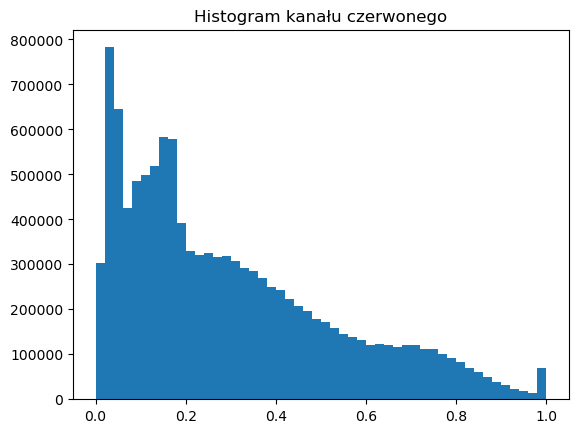

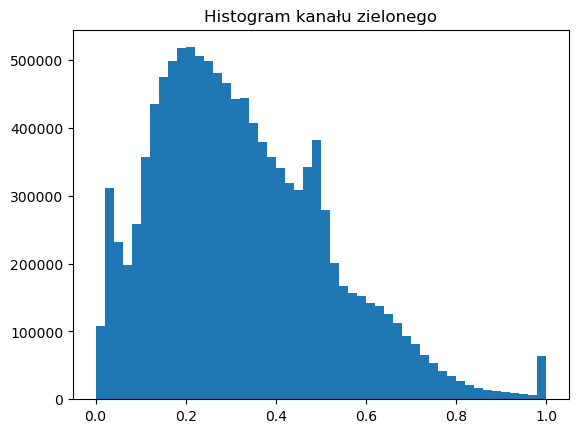

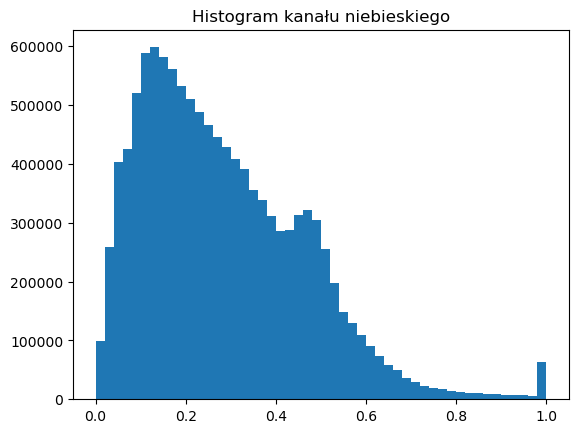

In [3]:
plt.hist(raster_rgb2[:, :, 0].flatten(), bins=50)
plt.title("Histogram kanału czerwonego")
plt.show()

plt.hist(raster_rgb2[:, :, 1].flatten(), bins=50)
plt.title("Histogram kanału zielonego")
plt.show()

plt.hist(raster_rgb2[:, :, 2].flatten(), bins=50)
plt.title("Histogram kanału niebieskiego")
plt.show()

3. Podziel wartości rastra na 9 równych części (3 x 3), a następnie podaj współrzędne w układzie odniesienia rastra środka każdej z tych części

In [ ]:
from rasterio.windows import Window

with rasterio.open(path + "B04.tif") as src:
    for row in range(3):
        row_start = row * src.height // 3
        row_end = (row + 1) * src.height // 3

        for col in range(3):
            col_start = col * src.width // 3
            col_end = (col + 1) * src.width // 3

            window = Window(
                col_start,
                row_start,
                col_end - col_start,
                row_end - row_start,
            )

            profile = src.profile.copy()
            profile.update(
                width=int(window.width),
                height=int(window.height),
                transform=src.window_transform(window),
            )

            with rasterio.open(f"part_{row + 1}_{col + 1}.tif", "w", **profile) as dst:
                dst.write(src.read(window=window))

In [10]:
for i in range(1, 4):
    for j in range(1, 4):
        with rasterio.open(f"part_{i}_{j}.tif") as src:
            center_x, center_y = src.transform * (src.width / 2, src.height / 2)
            print(f"part_{i}_{j}.tif Center: ({center_x}, {center_y})")

part_1_1.tif Center: (359445.0, 4176220.0)
part_1_2.tif Center: (373315.0, 4176220.0)
part_1_3.tif Center: (387185.0, 4176220.0)
part_2_1.tif Center: (359445.0, 4166920.0)
part_2_2.tif Center: (373315.0, 4166920.0)
part_2_3.tif Center: (387185.0, 4166920.0)
part_3_1.tif Center: (359445.0, 4157615.0)
part_3_2.tif Center: (373315.0, 4157615.0)
part_3_3.tif Center: (387185.0, 4157615.0)


4. Zapisz raster do 1 pliku RGB złożonego z zaciągniętych 3 kanałów